# ДЗ-1 Python

In [62]:
import pandas as pd
import numpy as np
import sys

## Задание 1. Оценка перспективности отрасли по EBIT

### Загрузка данных

In [2]:
excel_data = pd.read_excel("Реестр.xlsx", skiprows=2)

/home/ayakovlenko/.local/lib/python3.14/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [3]:
excel_data.head()

,№ п/п,Наименование / ФИО,Тип субъекта,Категория,ОГРН,ИНН,Основной вид деятельности,Регион,Район,Город,...,Дата исключения из реестра,Телефон,E-mail,WWW,Наличие лицензий,"Наличие заключенных договоров, контрактов","Производство инновационной, высокотехнологичной продукции",Участие в программах партнерства,Является социальным предприятием,Среднесписочная численность работников за предшествующий календарный год
0,1,""" МЕГАПОЛИС "" ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВ...",Юридическое лицо,Не является субъектом МСП,1027800523376,7801190028,41.2 Строительство жилых и нежилых зданий,78 - г.Санкт-Петербург,NaN,NaN,...,10.10.2021,NaN,NaN,NaN,Нет,Нет,Нет,Нет,Нет,NaN
1,2,""" СТАЛЬИНВЕСТСТРОЙ "" ОБЩЕСТВО С ОГРАНИЧЕННОЙ О...",Юридическое лицо,Не является субъектом МСП,1037800033545,7801227976,41.20 Строительство жилых и нежилых зданий,78 - г.Санкт-Петербург,NaN,NaN,...,10.08.2018,NaN,NaN,NaN,Нет,Нет,Нет,Нет,Нет,NaN
2,3,""" СТРОЙТЕХНИКА - М "" ОБЩЕСТВО С ОГРАНИЧЕННОЙ О...",Юридическое лицо,Не является субъектом МСП,1025204418293,5263039399,41.20 Строительство жилых и нежилых зданий,52 - Нижегородская область,NaN,г Нижний Новгород,...,10.07.2022,NaN,NaN,NaN,Нет,Нет,Нет,Нет,Нет,NaN
3,4,"""БАЗИС"" ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ",Юридическое лицо,Микропредприятие,1025204411682,5263025484,41.20 Строительство жилых и нежилых зданий,52 - Нижегородская область,NaN,г Нижний Новгород,...,NaN,NaN,NaN,NaN,Нет,Нет,Нет,Нет,Нет,1.0
4,5,"""БЕЛАГ"" ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ",Юридическое лицо,Не является субъектом МСП,1037800039276,7801123215,41.20 Строительство жилых и нежилых зданий,78 - г.Санкт-Петербург,NaN,NaN,...,10.07.2021,NaN,NaN,NaN,Нет,Нет,Нет,Нет,Нет,NaN


In [4]:
excel_data.columns

Index(['№ п/п', 'Наименование / ФИО', 'Тип субъекта', 'Категория', 'ОГРН',
       'ИНН', 'Основной вид деятельности', 'Регион', 'Район', 'Город',
       'Населенный пункт', 'Вновь созданный', 'Дата включения в реестр',
       'Дата исключения из реестра', 'Телефон', 'E-mail', 'WWW',
       'Наличие лицензий', 'Наличие заключенных договоров, контрактов',
       'Производство инновационной, высокотехнологичной продукции',
       'Участие в программах партнерства', 'Является социальным предприятием',
       'Среднесписочная численность работников за предшествующий календарный год'],
      dtype='str')

In [5]:
c_category = 'Категория'
c_type = 'Тип субъекта'
c_main_activity = 'Основной вид деятельности'
c_inn = "ИНН"

### Фильтрация данных

In [6]:
excel_data[c_type].unique()


<StringArray>
['Юридическое лицо', 'Индивидуальный предприниматель']
Length: 2, dtype: str

In [7]:
excel_data[c_category].unique()

<StringArray>
['Не является субъектом МСП',          'Микропредприятие',
         'Малое предприятие',       'Среднее предприятие']
Length: 4, dtype: str

In [8]:
excel_data[c_main_activity].unique()

<StringArray>
[ '41.2 Строительство жилых и нежилых зданий',
 '41.20 Строительство жилых и нежилых зданий',
     '41.10 Разработка строительных проектов',
                    '41 Строительство зданий',
      '41.1 Разработка строительных проектов']
Length: 5, dtype: str

In [9]:
subject_type_f = 'Юридическое лицо'
small_org_f = 'Малое предприятие'
mediun_org_f = 'Среднее предприятие'
main_activity_f = '41.20 Строительство жилых и нежилых зданий'

In [10]:
cat_filter = (excel_data[c_category] == small_org_f) | (excel_data[c_category] == mediun_org_f)
type_filter = excel_data[c_type] == subject_type_f
activity_filter = excel_data[c_main_activity] == main_activity_f

data_filter = cat_filter & type_filter & activity_filter

In [11]:
data = excel_data[data_filter]

In [12]:
data = data[["Наименование / ФИО", c_type, c_category, c_inn, c_main_activity, 'Регион', 'Район', 'Город', 'Населенный пункт']]

In [13]:
data.head()

,Наименование / ФИО,Тип субъекта,Категория,ИНН,Основной вид деятельности,Регион,Район,Город,Населенный пункт
19,"""КОРПОРАЦИЯ ВИТ"" (ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕ...",Юридическое лицо,Малое предприятие,5038038838,41.20 Строительство жилых и нежилых зданий,50 - Московская область,Пушкино г,NaN,NaN
51,"""ХОЗРАСЧЕТНАЯ СТРОИТЕЛЬНО-ТЕХНОЛОГИЧЕСКАЯ ФИРМ...",Юридическое лицо,Среднее предприятие,5027006369,41.20 Строительство жилых и нежилых зданий,50 - Московская область,NaN,г Дзержинский,NaN
4652,"АКЦИОНЕРНОЕ ОБЩЕСТВО ""777""",Юридическое лицо,Малое предприятие,1414006922,41.20 Строительство жилых и нежилых зданий,77 - г.Москва,NaN,NaN,NaN
4667,"АКЦИОНЕРНОЕ ОБЩЕСТВО ""АГРОТЕХИМПОРТ""",Юридическое лицо,Малое предприятие,3327332190,41.20 Строительство жилых и нежилых зданий,33 - Владимирская область,NaN,г Владимир,NaN
4673,"АКЦИОНЕРНОЕ ОБЩЕСТВО ""АКС""",Юридическое лицо,Малое предприятие,7816061297,41.20 Строительство жилых и нежилых зданий,78 - г.Санкт-Петербург,NaN,NaN,NaN


In [14]:
data[c_inn].info()
# Проверяю, что у всех строк присутствует ИНН, иначе не смогу найти инфу на сайте

<class 'pandas.Series'>
Index: 8927 entries, 19 to 580134
Series name: ИНН
Non-Null Count  Dtype
--------------  -----
8927 non-null   int64
dtypes: int64(1)
memory usage: 139.5 KB


### Парсинг

In [15]:
import requests
import json
from concurrent.futures import ThreadPoolExecutor
import threading

In [16]:
session = requests.Session()


#### Добавление ID организации по ее ИНН

In [17]:
c_ob_id = "ob_id"

In [18]:
thread_local = threading.local()

def get_session():
    if not hasattr(thread_local, "session"):
        thread_local.session = requests.Session()
    return thread_local.session

In [81]:
headers = {'User-Agent': 'Mozilla/5.0 (Macintosh; Intel Mac OS X 10_11_5) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/50.0.2661.102 Safari/537.36'}

def get_ob_id_url(inn):
    return f"https://bo.nalog.gov.ru/advanced-search/organizations?inn={inn}&page=0&size=0"

def get_ob_id_json(inn):
    session = get_session()
    res = session.get(get_ob_id_url(inn), headers=headers, timeout=10)
    res.raise_for_status()
    return res.json() 

def get_ob_id(inn):
    res_json = get_ob_id_json(inn)
    if res_json.get('empty'):
        return pd.NA
    return res_json.get('content')[0].get('id')


In [82]:
data = data.reset_index().drop(['index'], axis=1)
data.head()

,Наименование / ФИО,Тип субъекта,Категория,ИНН,Основной вид деятельности,Регион,Район,Город,Населенный пункт,ob_id,fin_res
0,"""КОРПОРАЦИЯ ВИТ"" (ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕ...",Юридическое лицо,Малое предприятие,5038038838,41.20 Строительство жилых и нежилых зданий,50 - Московская область,Пушкино г,NaN,NaN,5872486,"{'2023': {'current2300': -20665.0, 'current233..."
1,"""ХОЗРАСЧЕТНАЯ СТРОИТЕЛЬНО-ТЕХНОЛОГИЧЕСКАЯ ФИРМ...",Юридическое лицо,Среднее предприятие,5027006369,41.20 Строительство жилых и нежилых зданий,50 - Московская область,NaN,г Дзержинский,NaN,6900709,"{'2022': {'current2300': 40010.0, 'current2330..."
2,"АКЦИОНЕРНОЕ ОБЩЕСТВО ""777""",Юридическое лицо,Малое предприятие,1414006922,41.20 Строительство жилых и нежилых зданий,77 - г.Москва,NaN,NaN,NaN,4980670,"{'2021': {'current2300': 7940.0, 'current2330'..."
3,"АКЦИОНЕРНОЕ ОБЩЕСТВО ""АГРОТЕХИМПОРТ""",Юридическое лицо,Малое предприятие,3327332190,41.20 Строительство жилых и нежилых зданий,33 - Владимирская область,NaN,г Владимир,NaN,3867230,"{'2024': {'current2300': 61184.0, 'current2330..."
4,"АКЦИОНЕРНОЕ ОБЩЕСТВО ""АКС""",Юридическое лицо,Малое предприятие,7816061297,41.20 Строительство жилых и нежилых зданий,78 - г.Санкт-Петербург,NaN,NaN,NaN,7041303,"{'2023': {'current2300': None, 'current2330': ..."


In [83]:
chunk_size = 50

with ThreadPoolExecutor(max_workers = 10) as executor:
    for start in range(0, len(data), chunk_size):
        data.loc[start:start + chunk_size - 1, c_ob_id] = list(executor.map(get_ob_id, data[start:start+chunk_size][c_inn]))

In [84]:
data.head()

,Наименование / ФИО,Тип субъекта,Категория,ИНН,Основной вид деятельности,Регион,Район,Город,Населенный пункт,ob_id,fin_res
0,"""КОРПОРАЦИЯ ВИТ"" (ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕ...",Юридическое лицо,Малое предприятие,5038038838,41.20 Строительство жилых и нежилых зданий,50 - Московская область,Пушкино г,NaN,NaN,5872486,"{'2023': {'current2300': -20665.0, 'current233..."
1,"""ХОЗРАСЧЕТНАЯ СТРОИТЕЛЬНО-ТЕХНОЛОГИЧЕСКАЯ ФИРМ...",Юридическое лицо,Среднее предприятие,5027006369,41.20 Строительство жилых и нежилых зданий,50 - Московская область,NaN,г Дзержинский,NaN,6900709,"{'2022': {'current2300': 40010.0, 'current2330..."
2,"АКЦИОНЕРНОЕ ОБЩЕСТВО ""777""",Юридическое лицо,Малое предприятие,1414006922,41.20 Строительство жилых и нежилых зданий,77 - г.Москва,NaN,NaN,NaN,4980670,"{'2021': {'current2300': 7940.0, 'current2330'..."
3,"АКЦИОНЕРНОЕ ОБЩЕСТВО ""АГРОТЕХИМПОРТ""",Юридическое лицо,Малое предприятие,3327332190,41.20 Строительство жилых и нежилых зданий,33 - Владимирская область,NaN,г Владимир,NaN,3867230,"{'2024': {'current2300': 61184.0, 'current2330..."
4,"АКЦИОНЕРНОЕ ОБЩЕСТВО ""АКС""",Юридическое лицо,Малое предприятие,7816061297,41.20 Строительство жилых и нежилых зданий,78 - г.Санкт-Петербург,NaN,NaN,NaN,7041303,"{'2023': {'current2300': None, 'current2330': ..."


In [85]:
data = data.dropna(subset = [c_ob_id])

In [86]:
len(data)

8756

#### Парсинг необходимых данных из финансовых отчетов

In [87]:
c_fin_res = 'fin_res'

In [88]:
def get_financial_result_url(ob_id):
    return f"https://bo.nalog.gov.ru/nbo/organizations/{ob_id}/bfo/"

def get_financial_result_json(ob_id):
    url = get_financial_result_url(ob_id)
    session = get_session()
    result = session.get(url, headers = headers, timeout=10)
    result.raise_for_status()
    return result.json()


def get_financial_result(ob_id):
    res_json = get_financial_result_json(ob_id)
    result = dict()
    for year_res in res_json:
        year = year_res['period']
        year_fin_res = year_res['typeCorrections'][0]['correction']
        if 'financialResult' not in year_fin_res:
            return pd.NA
        year_fin_res = year_fin_res['financialResult']
        result[year] = dict()
        # Параметры для первого способа высчитывать ebit: 2300 + 2330
        result[year]['current2300'] = year_fin_res.get('current2300') # Прибыль (убыток) от продолжающейся деятельности до налогообложения
        result[year]['current2330'] = year_fin_res.get('current2330') # Проценты к уплате

        # Так как обнаружилось в процессе выполнения ДЗ, что предыдущие параметры присылают не все, добавляю еще эти
        # Чатгпт советовал эти не брать из-за ряда причин, но я возьму
        # ebit = 2400 + 2410 + 2330
        result[year]['current2400'] = year_fin_res.get('current2400') # Чистая прибыль 
        result[year]['current2410'] = year_fin_res.get('current2410') # Налог на прибыль

        # Для расчетов EBIT margin
        result[year]['current2110'] = year_fin_res.get('current2110') # Выручка

    return result

In [89]:
data = data.reset_index().drop(columns=['index'])

In [90]:
chunk_size = 100

with ThreadPoolExecutor(max_workers=10) as executor:
    for start in range(0, len(data), chunk_size):
        data.loc[start:start+chunk_size-1, c_fin_res] = list(executor.map(get_financial_result, data[start:start+chunk_size][c_ob_id]))
        # time.sleep(2)

In [91]:
data[c_fin_res].info()

<class 'pandas.Series'>
RangeIndex: 8756 entries, 0 to 8755
Series name: fin_res
Non-Null Count  Dtype 
--------------  ----- 
8756 non-null   object
dtypes: object(1)
memory usage: 68.5+ KB


In [92]:
data = data[~data[c_fin_res].isna()]

In [94]:
c_ebit = lambda y: f"ebit_{y}"
c_revenue = lambda y: f"Выручка_{y}"

In [130]:
def get_ebit_w1(profit_with_tax, interest):
    return profit_with_tax + np.abs(interest or 0)

def get_ebit_w2(profit, taxes, interest):
    return profit + np.abs(taxes or 0) + np.abs(interest or 0)

def get_ebit(current2300, current2330, current2400, current2410):
    if current2300 is not None:
        return get_ebit_w1(current2300, current2330)

    if current2400 is not None: 
        return get_ebit_w2(current2400, current2410, current2330)
        
    return pd.NA
    

In [131]:
year_start = 2021
year_end = 2025

for y in range(year_start, year_end+1):
    sy = str(y)
    data[c_ebit(y)] = data[c_fin_res].map(lambda res: get_ebit(res[sy]['current2300'], res[sy]['current2330'], res[sy]['current2400'], res[sy]['current2410']) if res.get(sy) else pd.NA)
    data[c_revenue(y)] = data[c_fin_res].map(lambda res: res[sy]['current2110'] if res.get(sy) else pd.NA)
    

In [133]:
data.head()

,Наименование / ФИО,Тип субъекта,Категория,ИНН,Основной вид деятельности,Регион,Район,Город,Населенный пункт,ob_id,...,ebit_2021,Выручка_2021,ebit_2022,Выручка_2022,ebit_2023,Выручка_2023,ebit_2024,Выручка_2024,ebit_2025,Выручка_2025
0,"""КОРПОРАЦИЯ ВИТ"" (ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕ...",Юридическое лицо,Малое предприятие,5038038838,41.20 Строительство жилых и нежилых зданий,50 - Московская область,Пушкино г,NaN,NaN,5872486,...,9031.0,184044.0,20360.0,118633.0,-17331.0,108966.0,-18417.0,112540.0,11412.0,140064.0
1,"""ХОЗРАСЧЕТНАЯ СТРОИТЕЛЬНО-ТЕХНОЛОГИЧЕСКАЯ ФИРМ...",Юридическое лицо,Среднее предприятие,5027006369,41.20 Строительство жилых и нежилых зданий,50 - Московская область,NaN,г Дзержинский,NaN,6900709,...,25839.0,584219.0,42801.0,683396.0,730016.0,1565001.0,37887.0,429496.0,753572.0,1287757.0
2,"АКЦИОНЕРНОЕ ОБЩЕСТВО ""777""",Юридическое лицо,Малое предприятие,1414006922,41.20 Строительство жилых и нежилых зданий,77 - г.Москва,NaN,NaN,NaN,4980670,...,7940.0,685315.0,7409.0,938983.0,28513.0,1002486.0,71787.0,1107569.0,83370.0,1927383.0
3,"АКЦИОНЕРНОЕ ОБЩЕСТВО ""АГРОТЕХИМПОРТ""",Юридическое лицо,Малое предприятие,3327332190,41.20 Строительство жилых и нежилых зданий,33 - Владимирская область,NaN,г Владимир,NaN,3867230,...,26125.0,584483.0,38067.0,458713.0,50126.0,1031417.0,61184.0,1297470.0,88371.0,1158867.0
4,"АКЦИОНЕРНОЕ ОБЩЕСТВО ""АКС""",Юридическое лицо,Малое предприятие,7816061297,41.20 Строительство жилых и нежилых зданий,78 - г.Санкт-Петербург,NaN,NaN,NaN,7041303,...,1385.0,179874.0,574.0,61921.0,706.0,116186.0,14649.0,782668.0,3646.0,288686.0


### Оценка, насколько область перспективна

Буду оценивать по показателю EBIT Margin:

$Margin = \frac{EBIT}{revenue}$

In [134]:
c_margin = lambda y: f"margin_{y}"

In [161]:
year_start = 2021
year_end = 2025


def count_margin(ebit, revenue):
    if pd.isna(revenue) or pd.isna(ebit) or revenue == 0:
        return pd.NA
    return np.round(ebit / revenue * 100, 2)

for y in range(year_start, year_end+1):
    data[c_margin(y)] = data.apply(lambda row: count_margin(row[c_ebit(y)], row[c_revenue(y)]), axis = 1)

In [162]:
data.head()

,Наименование / ФИО,Тип субъекта,Категория,ИНН,Основной вид деятельности,Регион,Район,Город,Населенный пункт,ob_id,...,Выручка_2023,ebit_2024,Выручка_2024,ebit_2025,Выручка_2025,margin_2021,margin_2022,margin_2023,margin_2024,margin_2025
0,"""КОРПОРАЦИЯ ВИТ"" (ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕ...",Юридическое лицо,Малое предприятие,5038038838,41.20 Строительство жилых и нежилых зданий,50 - Московская область,Пушкино г,NaN,NaN,5872486,...,108966.0,-18417.0,112540.0,11412.0,140064.0,4.91,17.16,-15.9,-16.36,8.15
1,"""ХОЗРАСЧЕТНАЯ СТРОИТЕЛЬНО-ТЕХНОЛОГИЧЕСКАЯ ФИРМ...",Юридическое лицо,Среднее предприятие,5027006369,41.20 Строительство жилых и нежилых зданий,50 - Московская область,NaN,г Дзержинский,NaN,6900709,...,1565001.0,37887.0,429496.0,753572.0,1287757.0,4.42,6.26,46.65,8.82,58.52
2,"АКЦИОНЕРНОЕ ОБЩЕСТВО ""777""",Юридическое лицо,Малое предприятие,1414006922,41.20 Строительство жилых и нежилых зданий,77 - г.Москва,NaN,NaN,NaN,4980670,...,1002486.0,71787.0,1107569.0,83370.0,1927383.0,1.16,0.79,2.84,6.48,4.33
3,"АКЦИОНЕРНОЕ ОБЩЕСТВО ""АГРОТЕХИМПОРТ""",Юридическое лицо,Малое предприятие,3327332190,41.20 Строительство жилых и нежилых зданий,33 - Владимирская область,NaN,г Владимир,NaN,3867230,...,1031417.0,61184.0,1297470.0,88371.0,1158867.0,4.47,8.3,4.86,4.72,7.63
4,"АКЦИОНЕРНОЕ ОБЩЕСТВО ""АКС""",Юридическое лицо,Малое предприятие,7816061297,41.20 Строительство жилых и нежилых зданий,78 - г.Санкт-Петербург,NaN,NaN,NaN,7041303,...,116186.0,14649.0,782668.0,3646.0,288686.0,0.77,0.93,0.61,1.87,1.26


<Axes: >

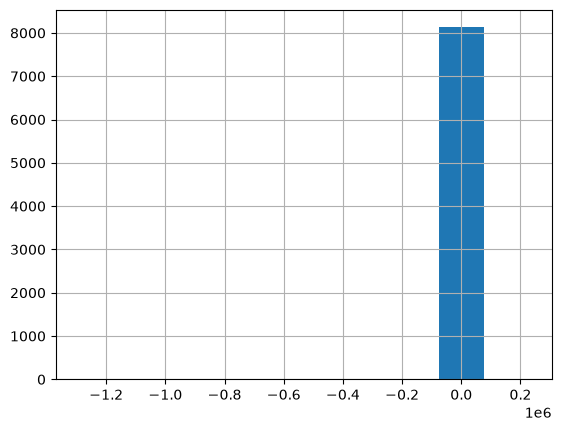

In [170]:
data[c_margin(2021)].hist()

In [186]:
import numpy as np

<Axes: >

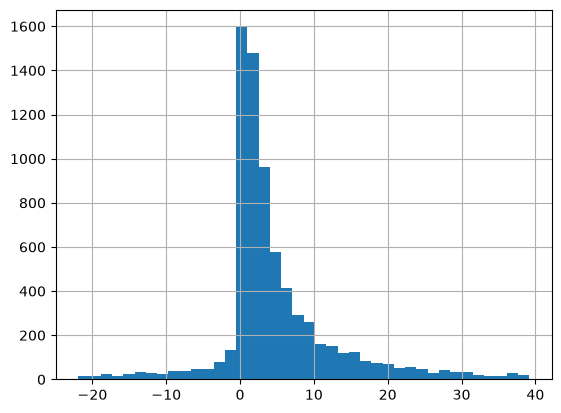

In [193]:
y = 2021
n, x = np.percentile(data[c_margin(y)].dropna(), [5, 95])
data[(data[c_margin(y)] > n) & (data[c_margin(y)] < x)][c_margin(y)].hist(bins = 40)

<Axes: >

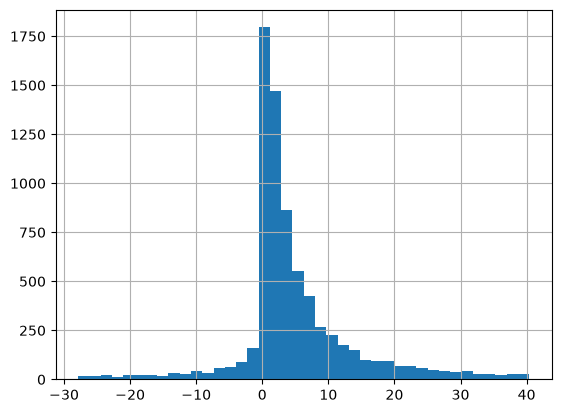

In [194]:
y = 2022
n, x = np.percentile(data[c_margin(y)].dropna(), [5, 95])
data[(data[c_margin(y)] > n) & (data[c_margin(y)] < x)][c_margin(y)].hist(bins = 40)

<Axes: >

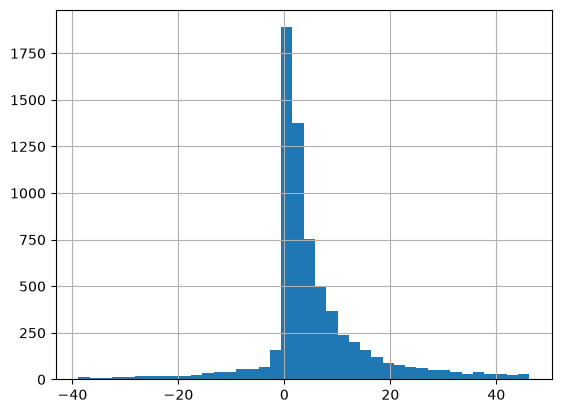

In [195]:
y = 2023
n, x = np.percentile(data[c_margin(y)].dropna(), [5, 95])
data[(data[c_margin(y)] > n) & (data[c_margin(y)] < x)][c_margin(y)].hist(bins = 40)

<Axes: >

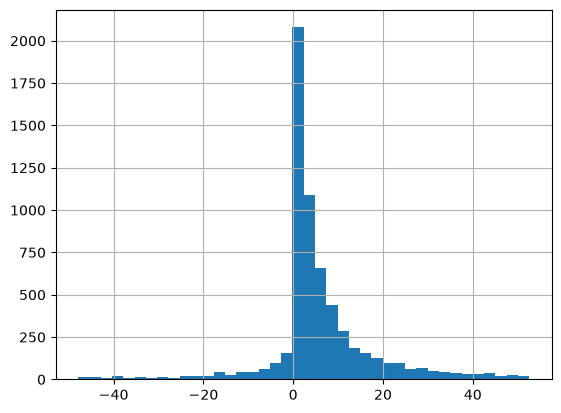

In [196]:
y = 2024
n, x = np.percentile(data[c_margin(y)].dropna(), [5, 95])
data[(data[c_margin(y)] > n) & (data[c_margin(y)] < x)][c_margin(y)].hist(bins = 40)

<Axes: >

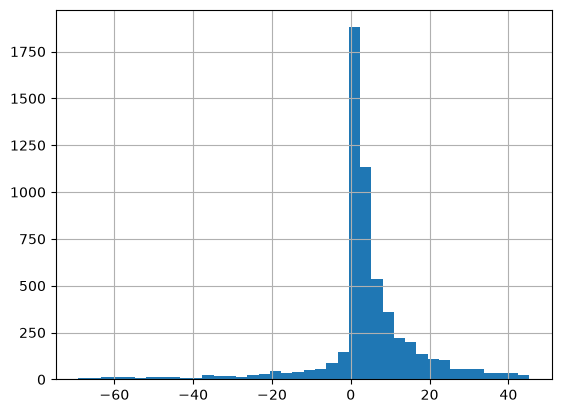

In [197]:
y = 2025
n, x = np.percentile(data[c_margin(y)].dropna(), [5, 95])
data[(data[c_margin(y)] > n) & (data[c_margin(y)] < x)][c_margin(y)].hist(bins = 40)

<Axes: xlabel='year'>

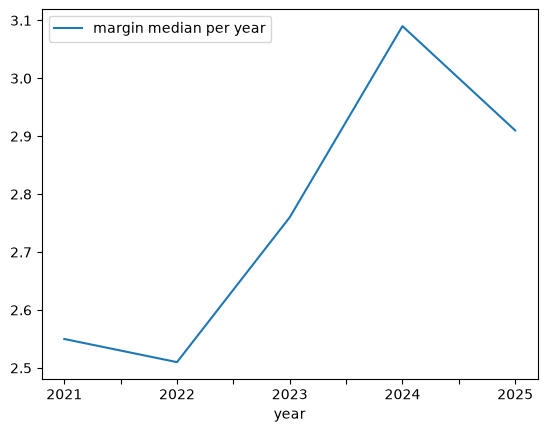

In [217]:
y_start = 2021
y_end = 2025
medians = pd.DataFrame(range(y_start, y_end+1))
medians = medians.rename(columns = {0: "year"})
medians['margin median per year'] = medians['year'].map(lambda y: np.round(np.median(data[c_margin(y)].dropna()), 2))
medians['year'] = medians['year'].map(str)
medians = medians.set_index('year')
medians.plot()
# for y in range(y_start, y_end+1):
#     medians.append(np.median(data[c_margin(y)].dropna()))




**Вывод** 
- Показатель медианы EBIT margin хоть и положительный, но недостаточно высокий, чтобы отрасль можно было назвать перспективной, она скорее стагнирует (чтобы она была перспективной, полагаю, медианное значение должно быть на уровне хотя бы 10-15 процентов, так как на уровне компании за хороший прогресс считается около 20%)


## Задание 2. Построение графиков

In [264]:
task_2_data = data[[c_inn, c_fin_res]]

In [265]:
c_profit = lambda y: f"profit_{y}"

In [266]:
y_start = 2021
y_end = 2025

for y in range(y_start, y_end+1):
    sy = str(y)
    task_2_data[c_profit(y)] = task_2_data[c_fin_res].map(lambda x: x[sy]['current2400'] if x.get(sy) else pd.NA)

In [267]:
task_2_data.head()

,ИНН,fin_res,profit_2021,profit_2022,profit_2023,profit_2024,profit_2025
0,5038038838,"{'2023': {'current2300': -20665.0, 'current233...",3080.0,19518.0,-20913.0,-20129.0,-520.0
1,5027006369,"{'2022': {'current2300': 40010.0, 'current2330...",20376.0,31442.0,582441.0,28998.0,704973.0
2,1414006922,"{'2021': {'current2300': 7940.0, 'current2330'...",2092.0,3375.0,19889.0,54850.0,60542.0
3,3327332190,"{'2024': {'current2300': 61184.0, 'current2330...",20565.0,30374.0,40101.0,47723.0,65830.0
4,7816061297,"{'2023': {'current2300': None, 'current2330': ...",1077.0,444.0,565.0,11674.0,2542.0


In [294]:
y_base = 2024
y_current = 2025

def c_diff_profit(b, c):
    return f'profit diff {b}-{c} (%)'

task_2_data[c_diff_profit(y_base, y_current)] = task_2_data[c_profit(y_current)] - task_2_data[c_profit(y_base)]
task_2_data[c_diff_profit(y_base, y_current)] = task_2_data.apply(lambda row: row[c_diff_profit(y_base, y_current)] / row[c_profit(y_base)] if not pd.isna(row[c_profit(y_base)]) and row[c_profit(y_base)] != 0 else pd.NA, axis=1)
task_2_data[c_diff_profit(y_base, y_current)] = task_2_data[c_diff_profit(y_base, y_current)].map(lambda x: x * 100).map(lambda x: np.round(x) if not pd.isna(x) else x)

In [295]:
task_2_data

,ИНН,fin_res,profit_2021,profit_2022,profit_2023,profit_2024,profit_2025,profit diff (%),profit diff 2021-2025 (%),profit diff 2022-2025 (%),profit diff 2024-2025 (%)
0,5038038838,"{'2023': {'current2300': -20665.0, 'current233...",3080.0,19518.0,-20913.0,-20129.0,-520.0,-117.0,-117.0,-103.0,-97.0
1,5027006369,"{'2022': {'current2300': 40010.0, 'current2330...",20376.0,31442.0,582441.0,28998.0,704973.0,3360.0,3360.0,2142.0,2331.0
2,1414006922,"{'2021': {'current2300': 7940.0, 'current2330'...",2092.0,3375.0,19889.0,54850.0,60542.0,2794.0,2794.0,1694.0,10.0
3,3327332190,"{'2024': {'current2300': 61184.0, 'current2330...",20565.0,30374.0,40101.0,47723.0,65830.0,220.0,220.0,117.0,38.0
4,7816061297,"{'2023': {'current2300': None, 'current2330': ...",1077.0,444.0,565.0,11674.0,2542.0,136.0,136.0,473.0,-78.0
...,...,...,...,...,...,...,...,...,...,...,...
8751,2301091157,"{'2021': {'current2300': None, 'current2330': ...",-17579.0,-19260.0,-61513.0,-17777.0,12076.0,-169.0,-169.0,-163.0,-168.0
8752,2301083597,"{'2022': {'current2300': None, 'current2330': ...",-27021.0,-23759.0,-17307.0,-69742.0,-27507.0,2.0,2.0,16.0,-61.0
8753,6504043928,"{'2024': {'current2300': -93467.0, 'current233...",6091.0,3167.0,-516607.0,-93467.0,-14501.0,-338.0,-338.0,-558.0,-84.0
8754,2002001476,"{'2025': {'current2300': 1597.0, 'current2330'...",1049.0,4126.0,4941.0,1656.0,1198.0,14.0,14.0,-71.0,-28.0


<Axes: >

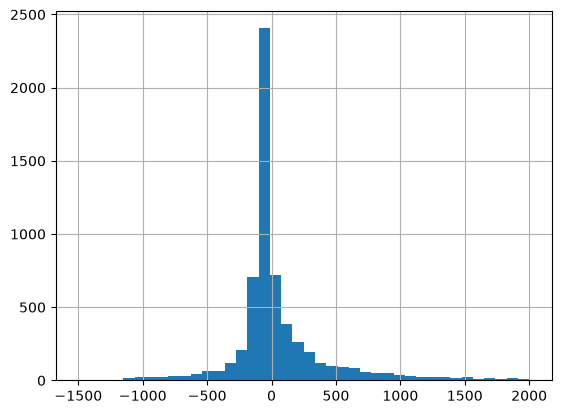

In [316]:
b, c = 2021, 2025
n, x = np.percentile(task_2_data[c_diff_profit(b, c)].dropna(), [5, 95])
task_2_data[(task_2_data[c_diff_profit(b, c)] > n) & (task_2_data[c_diff_profit(b, c)] < x)][c_diff_profit(b, c)].dropna().hist(bins = 40, range = (-1500, 2000))

<Axes: >

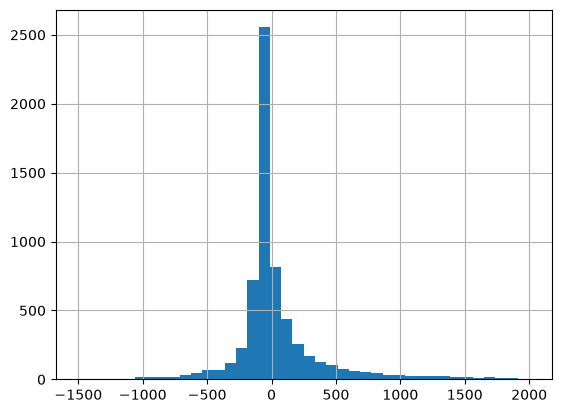

In [317]:
b, c = 2022, 2025
n, x = np.percentile(task_2_data[c_diff_profit(b, c)].dropna(), [5, 95])
task_2_data[(task_2_data[c_diff_profit(b, c)] > n) & (task_2_data[c_diff_profit(b, c)] < x)][c_diff_profit(b, c)].dropna().hist(bins = 40, range = (-1500, 2000))

<Axes: >

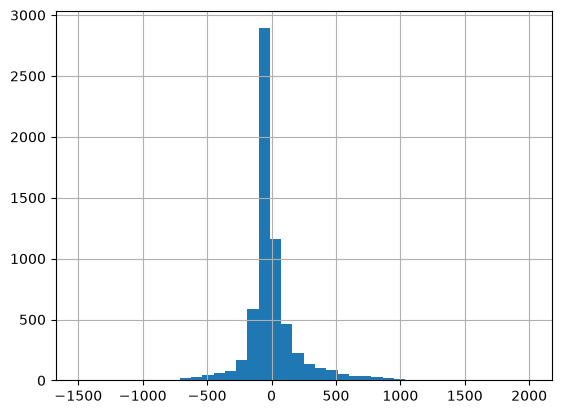

In [318]:
b, c = 2024, 2025
n, x = np.percentile(task_2_data[c_diff_profit(b, c)].dropna(), [5, 95])
task_2_data[(task_2_data[c_diff_profit(b, c)] > n) & (task_2_data[c_diff_profit(b, c)] < x)][c_diff_profit(b, c)].dropna().hist(bins = 40, range = (-1500, 2000))

**Вывод**
- Видим что большинство компаний имеет отрицательную тенденцию во всех трех случаях разницы последнего показателя чистой прибыли со значением из предыдущих лет. Более того, чем ближе к 